In [1]:
import pandas as pd
pd.options.display.float_format = '{:.0f}'.format

# 1. Data Loading

In [2]:
import pandas as pd

# Using a raw string (r"...") for the Windows file path
df = pd.read_csv(r"C:\Users\chowy\Desktop\Datathon_Analysis.xlsx.csv")
# Display the first few rows to confirm it loaded correctly
df.head()

C:\Users\chowy\AppData\Local\Temp\ipykernel_34452\1236803907.py:4: DtypeWarning: Columns (0,20) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\chowy\Desktop\Datathon_Analysis.xlsx.csv")


,DISCLAIMER,EPOCH_SECONDS,CURRENCY_CODE,USD_AMOUNT,ORDERING_BIC8,BENEFICIARY_BIC8,BIC8_PATH,TOTAL_DURATION,CONTINUITY_QFLAG,CURRENCY_CONVERSION_COUNT,...,TRANSACTION_TYPE_CODE,ORDERING_ACCOUNT,BENEFICIARY_ACCOUNT,ORDERING_DETAILS,ORDERING_TOKENS,BENEFICIARY_DETAILS,BENEFICIARY_TOKENS,ORDERING_TYPE,BENEFICIARY_TYPE,ANOMALY_TYPE
0,WARNING: This dataset contains purely fictitio...,1685363344,USD,500,0621US30,0219US30,0621US30;0219US30,4,Y,0,...,Direct,_FAKE_00.-0/0092Y9262,_FAKE_0009559K28N,/00.-0/0092Y9262\nSCHULTZ PLC 38626 CHRISTENSE...,/<chr:99.-9/9999A9999>\n<line_break:35><busine...,/0009559K28N\nS MRDHAA 66 SIRAJROAD 2711 GAAIB...,/<chr:9999999A99A>\n<line_break:35><chr:A> <la...,B,C,NaN
1,NaN,1686659145,TRY,1390,0024TRI0,0380CNB0,0024TRI0;0380CNB0,396,Y,1,...,Direct,_FAKE_TR53002400000000890222,_FAKE_0000000008A79136,/TR53002400000000890222\nCALIK 1162 SERAFEDDIN...,/<iban:22>\n<line_break:35><business:5> <chr:9...,//0000000008A79136\nGUI LAN XIE DZUO TAO LU...,/<separator:/><chr:9999999999A99999>\n<first_n...,B,C,NaN
2,NaN,1688492312,GBP,3972,0007JEH0,0295GB20,0007JEH0;0295GB20,3,Y,0,...,Direct,_FAKE_00 000 000B0623 133W,_FAKE_GB30029500000000623158,"/00 000 000B0623 133W\n1/GORDON, SMITH AND MAR...",/<chr:99 999 999A9999 999A>\n<other_words:26>\...,/GB30029500000000623158\nW GUI XIANG YZUO XI...,/<iban:22>\n<chr:A> <last_name:10> <chr:AAAA >...,B,C,NaN
3,NaN,1684465569,SGD,1921,0203SGS0,0037DEF0,0203SGS0;0405US30;0037DEF0,4341,Y,2,...,Indirect,_FAKE_00000 F00/08/57/6/40,_FAKE_DE49003700000000292310,/00000 F00/08/57/6/40\nPERUM WASKITA JL. DIPEN...,/<chr:99999 A99/99/99/9/99>\n<line_break:35><b...,/DE49003700000000292310\nM ALBA 80036 CIRCUNVA...,/<iban:22>\n<other_words:6> <last_name:4> <chr...,B,C,NaN
4,NaN,1686000776,EUR,22131,0017DEF0,0087ZAJ0,0017DEF0;0087ZAJ0,20,Y,1,...,Direct,_FAKE_DE13001700000000291498,_FAKE_ 0000000.00099.3989,/DE13001700000000291498\nKREUSEL 1-9 ANA-BIRNB...,/<iban:22>\n<line_break:35><business:7> <chr:9...,/ 0000000.00099.3989\nMHWRSZN YRN KHWDRW SHHRS...,/<chr: 9999999.99999.9999>\n<business:18> <cit...,B,B,NaN


# DataCleaning & Preparation

In [38]:
import numpy as np
import pandas as pd

# Define schema and structure categories from the competition pipeline
NUMERIC = [
    "epoch_seconds",
    "usd_amount",
    "total_duration",
    "currency_conversion_count",
    "participant_count",
]
INTEGER = set(NUMERIC) - {"usd_amount"}
CATEGORIES = [
    "currency_code",
    "continuity_qflag",
    "transaction_type_code",
    "ordering_type",
    "beneficiary_type",
    "anomaly_type",
]
STRUCTURED = NUMERIC + CATEGORIES + ["ordering_bic8", "beneficiary_bic8", "bic8_path"]


def clean_payment_data(chunk: pd.DataFrame, offset: int = 0) -> tuple[pd.DataFrame, list[str]]:
  # 1. Normalize column names to lowercase and strip whitespace
  chunk.columns = [str(c).strip().lower() for c in chunk.columns]

  # 2. Clean structured fields (whitespace stripping and uppercase conversion for specific codes)
  for c in STRUCTURED:
    if c in chunk.columns:
      old = chunk[c]
      new = old.str.strip()
      if c in {
          "currency_code",
          "ordering_bic8",
          "beneficiary_bic8",
          "continuity_qflag",
          "ordering_type",
          "beneficiary_type",
      }:
        new = new.str.upper()
      chunk[c] = new

  # 3. Handle disclaimer and add source record tracking index
  if "disclaimer" in chunk.columns:
    chunk = chunk.drop(columns="disclaimer")

  chunk.insert(
      0, "source_record", np.arange(offset + 1, offset + len(chunk) + 1)
  )

  # 4. Initialize quality flags container
  flags = pd.Series("", index=chunk.index, dtype="string")

  def flag(mask: pd.Series, name: str) -> None:
    nonlocal flags
    mask = mask.fillna(False)
    flags.loc[mask] = flags.loc[mask] + name + ";"

  # 5. Parse numeric validations and bounds
  parsed = {}
  for c in NUMERIC:
    if c in chunk.columns:
      values = pd.to_numeric(chunk[c], errors="coerce")
      finite = pd.Series(
          np.isfinite(values.to_numpy(dtype=float, na_value=np.nan)),
          index=chunk.index,
      )
      invalid = chunk[c].ne("") & ~finite
      flag(chunk[c].eq(""), f"missing_{c}")
      flag(invalid, f"invalid_{c}")
      valid = values.where(finite)
      parsed[c] = valid
      flag(valid.lt(0), f"negative_{c}")
      if c in INTEGER:
        flag(valid.mod(1).ne(0) & valid.notna(), f"non_integer_{c}")

  # 6. Convert epoch seconds to UTC datetime
  if "epoch_seconds" in chunk.columns and "epoch_seconds" in parsed:
    epoch = parsed["epoch_seconds"]
    dates = pd.to_datetime(
        epoch.where(epoch.between(-62135596800, 253402300799)),
        unit="s",
        utc=True,
        errors="coerce",
    )
    flag(
        parsed["epoch_seconds"].notna() & dates.isna(),
        "timestamp_out_of_range",
    )
    chunk["payment_datetime_utc"] = (
        dates.dt.strftime("%Y-%m-%dT%H:%M:%S.%fZ").fillna("")
    )

  # 7. Structural checks for formatting and path validations
  if "currency_code" in chunk.columns:
    flag(
        ~chunk.currency_code.str.fullmatch(r"[A-Z]{3}"), "currency_format"
    )
  if "continuity_qflag" in chunk.columns:
    flag(
        ~chunk.continuity_qflag.isin(["Y", "N"]),
        "unknown_continuity_flag",
    )

  for c in ["ordering_bic8", "beneficiary_bic8"]:
    if c in chunk.columns:
      flag(
          ~chunk[c].str.fullmatch(r"[A-Z0-9]{8}"), f"invalid_{c}_format"
      )

  if (
      "bic8_path" in chunk.columns
      and "participant_count" in parsed
      and "ordering_bic8" in chunk.columns
      and "beneficiary_bic8" in chunk.columns
  ):
    path = chunk.bic8_path.str.split(";")
    flag(
        path.str.len().ne(parsed["participant_count"])
        & parsed["participant_count"].notna(),
        "path_participant_count_mismatch",
    )
    flag(path.str[0].ne(chunk.ordering_bic8), "path_ordering_endpoint_mismatch")
    flag(
        path.str[-1].ne(chunk.beneficiary_bic8),
        "path_beneficiary_endpoint_mismatch",
    )

  for c in [
      "ordering_account",
      "beneficiary_account",
      "ordering_details",
      "beneficiary_details",
      "bic8_path",
  ]:
    if c in chunk.columns:
      flag(chunk[c].str.strip().eq(""), f"missing_{c}")

  chunk["quality_flags"] = flags.str.rstrip(";")
  return chunk

In [41]:
import pandas as pd

# Create the summary table for row count, missing values, and unique counts per column
summary_df = pd.DataFrame(
    {
        "Row Count": len(df),
        "Missing Count": df.isnull().sum(),
        "Unique Count": df.nunique(),
    }
)

# Display the resulting summary table
summary_df

,Row Count,Missing Count,Unique Count
EPOCH_SECONDS,10000000,0,5085929
CURRENCY_CODE,10000000,0,155
USD_AMOUNT,10000000,0,3464639
ORDERING_BIC8,10000000,0,8392
BENEFICIARY_BIC8,10000000,0,8266
BIC8_PATH,10000000,0,4403689
TOTAL_DURATION,10000000,0,10151
CONTINUITY_QFLAG,10000000,0,2
CURRENCY_CONVERSION_COUNT,10000000,0,18
PARTICIPANT_COUNT,10000000,0,19


In [43]:
# 1. Top 10 Banks (ORDERING_BIC8) by Volume and Anomaly Rate
bank_volume = (
    df.groupby('ORDERING_BIC8')
    .agg(
        total_transactions=('USD_AMOUNT', 'count'),
        total_usd_volume=('USD_AMOUNT', 'sum'),
        anomaly_count=('is_anomaly', 'sum'),
    )
    .assign(anomaly_rate=lambda x: (x['anomaly_count'] / x['total_transactions']) * 100)
)

print('--- Top 10 Banks by Total Transaction Volume ---')
display(bank_volume.sort_values(by='total_usd_volume', ascending=False).head(10))

print('\n--- Top 10 Banks by Anomaly Rate (Min 10 transactions) ---')
valid_banks = bank_volume[bank_volume['total_transactions'] >= 10]
display(valid_banks.sort_values(by='anomaly_rate', ascending=False).head(10))

# 2. Top 10 Accounts (ORDERING_ACCOUNT) by Volume and Anomaly Rate
account_volume = (
    df.groupby('ORDERING_ACCOUNT')
    .agg(
        total_transactions=('USD_AMOUNT', 'count'),
        total_usd_volume=('USD_AMOUNT', 'sum'),
        anomaly_count=('is_anomaly', 'sum'),
    )
    .assign(anomaly_rate=lambda x: (x['anomaly_count'] / x['total_transactions']) * 100)
)

print('\n--- Top 10 Accounts by Total Transaction Volume ---')
display(account_volume.sort_values(by='total_usd_volume', ascending=False).head(10))

print('\n--- Top 10 Accounts by Anomaly Rate (Min 5 transactions) ---')
valid_accounts = account_volume[account_volume['total_transactions'] >= 5]
display(valid_accounts.sort_values(by='anomaly_rate', ascending=False).head(10))

--- Top 10 Banks by Total Transaction Volume ---


,total_transactions,total_usd_volume,anomaly_count,anomaly_rate
ORDERING_BIC8,,,,
0004MCM0,35271,24977766642,20,0
0070LUL0,21027,20967686935,12,0
0033US30,70288,15668244156,21,0
0064IT20,3298,14093106808,2,0
0005ILI0,336,12855150873,1,0
0085BEB0,89424,10844091399,41,0
0004IMD0,154396,10579507021,74,0
0201HKH0,8291,10157669062,4,0
0309CHZ0,130375,10055547505,62,0



--- Top 10 Banks by Anomaly Rate (Min 10 transactions) ---


,total_transactions,total_usd_volume,anomaly_count,anomaly_rate
ORDERING_BIC8,,,,
0112INB0,11,7878,7,64
0007KG20,12,4011,6,50
0015EGC0,20,12222,7,35
0000TDN0,21,8089,6,29
0059CNB0,25,33212,7,28
0001ETA0,24,9908,6,25
0029EGC0,37,657648,7,19
0041EGC0,27,36966,5,19
0008BFB0,17,2577,3,18



--- Top 10 Accounts by Total Transaction Volume ---


,total_transactions,total_usd_volume,anomaly_count,anomaly_rate
ORDERING_ACCOUNT,,,,
_FAKE_LU87007000000000669775,15172,20555801461,7,0
_FAKE_MC00000400000000675799,13518,14174269840,5,0
_FAKE_IT39006400000000616668,67,13901577428,1,1
_FAKE_IL79000500000000418731,116,12851123663,1,1
_FAKE_MC05000400000000675804,13945,10136327762,12,0
_FAKE_00-37751 -/7 /HKD,3497,9371043530,1,0
_FAKE_RO57001300000000822908,63,8300048332,1,2
_FAKE_DE47027500000000291823,508,7450007918,1,0
_FAKE_41GBP/9 1 67,75803,6784641327,30,0



--- Top 10 Accounts by Anomaly Rate (Min 5 transactions) ---


,total_transactions,total_usd_volume,anomaly_count,anomaly_rate
ORDERING_ACCOUNT,,,,
_FAKE_000000-694N897,5,552,5,100
_FAKE_0000000001A68353,7,4227,7,100
_FAKE_000Y0D004091P43O,8,10,8,100
_FAKE_000 4P40251 V,7,64,7,100
_FAKE_00E004JINRR40D868,6,1514,6,100
_FAKE_000000000/00866811,6,57131,6,100
_FAKE_-00W00717029-,6,628,6,100
_FAKE_0000JN4V453L45,8,424,8,100
_FAKE_Z007.62818,6,5932,6,100


# Summary Statistics of Numeric Columns

In [4]:
# Summary statistics for numeric columns
print("--- Numeric Columns Describe ---")
print(df[['USD_AMOUNT', 'TOTAL_DURATION', 'CURRENCY_CONVERSION_COUNT']].describe())

# Check missing values per column
print("\n--- Missing Values Count ---")
print(df.isnull().sum())

--- Numeric Columns Describe ---
       USD_AMOUNT  TOTAL_DURATION  CURRENCY_CONVERSION_COUNT
count    10000000        10000000                   10000000
mean        97204             772                          1
std       9909715            1228                          1
min             0               2                          0
25%           634              26                          1
50%          3662              56                          1
75%         19960            1105                          2
max   15664132213           21649                         17

--- Missing Values Count ---
EPOCH_SECONDS                0
CURRENCY_CODE                0
USD_AMOUNT                   0
ORDERING_BIC8                0
BENEFICIARY_BIC8             0
BIC8_PATH                    0
TOTAL_DURATION               0
CONTINUITY_QFLAG             0
CURRENCY_CONVERSION_COUNT    0
PARTICIPANT_COUNT            0
TRANSACTION_TYPE_CODE        0
ORDERING_ACCOUNT             0
BENEFICIARY_ACCO

In [42]:
# Calculate mean and median for USD_AMOUNT and TOTAL_DURATION per ANOMALY_TYPE
anomaly_summary = df.groupby('ANOMALY_TYPE').agg(
    mean_usd_amount=('USD_AMOUNT', 'mean'),
    median_usd_amount=('USD_AMOUNT', 'median'),
    mean_duration=('TOTAL_DURATION', 'mean'),
    median_duration=('TOTAL_DURATION', 'median'),
    transaction_count=('USD_AMOUNT', 'count')
).reset_index()

# Display the resulting summary table
anomaly_summary

,ANOMALY_TYPE,mean_usd_amount,median_usd_amount,mean_duration,median_duration,transaction_count
0,ACCOUNT_REPLACEMENT_SCAM,57325,3977,1159,571,649
1,CEO_SCAM,1384870,20602,1179,741,945
2,CUSTOMER_RECALL,98437,3164,719,53,317
3,DUPLICATE_PAYMENT,142348,2889,921,261,679
4,FAT_FINGER_MISTAKE,90277011,260241,741,53,1940
5,Normal,79598,3663,771,56,9992994
6,ROMANCE_SCAM,1958,109,1558,1148,2476


# Univariate Distribution Plots

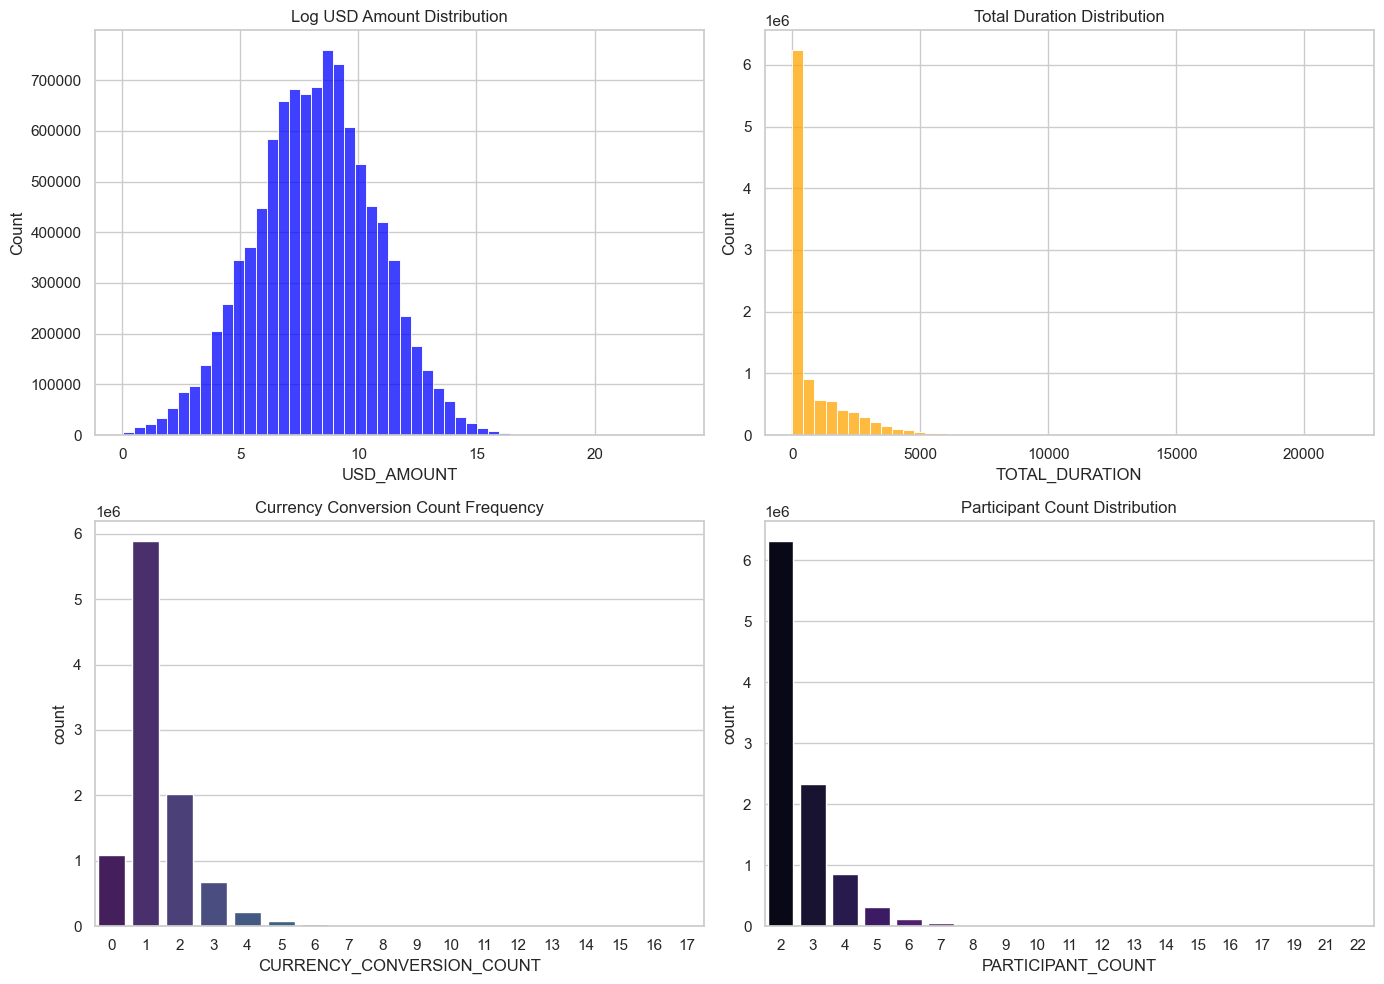

In [5]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# Univariate plots for numeric columns
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. USD Amount (Log scale)
sns.histplot(df['LOG_USD_AMOUNT'] if 'LOG_USD_AMOUNT' in df.columns else np.log1p(df['USD_AMOUNT']), 
             bins=50, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Log USD Amount Distribution')

# 2. Total Duration
sns.histplot(df['TOTAL_DURATION'], bins=50, ax=axes[0, 1], color='orange')
axes[0, 1].set_title('Total Duration Distribution')

# 3. Currency Conversion Count
sns.countplot(x='CURRENCY_CONVERSION_COUNT', data=df, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Currency Conversion Count Frequency')

# 4. Participant Count (if available) or Boxplot of Log USD Amount
if 'PARTICIPANT_COUNT' in df.columns:
    sns.countplot(x='PARTICIPANT_COUNT', data=df, ax=axes[1, 1], palette='magma')
    axes[1, 1].set_title('Participant Count Distribution')
else:
    sns.boxplot(x=df['USD_AMOUNT'], ax=axes[1, 1], color='green')
    axes[1, 1].set_title('USD Amount Boxplot')

plt.tight_layout()
plt.show()

In [49]:
# Check mean, median, and max USD amount grouped by Currency Code
currency_amount_summary = df.groupby('CURRENCY_CODE')['USD_AMOUNT'].agg(
    count='count',
    mean_usd='mean',
    median_usd='median',
    max_usd='max'
).sort_values(by='mean_usd', ascending=False)

display(currency_amount_summary.head(15))

,count,mean_usd,median_usd,max_usd
CURRENCY_CODE,,,,
GMD,506,747002,117,374992902
ILS,49045,426227,3359,12846432125
RON,29348,327850,2212,8297209027
KYD,41531,226073,9138,3355394328
CAD,111146,132531,4706,3484752232
HKD,197458,130344,4893,8910968294
USD,1702991,129553,6373,4287956200
SGD,367648,123235,6405,1650198340
BMD,8877,117000,5439,40952372


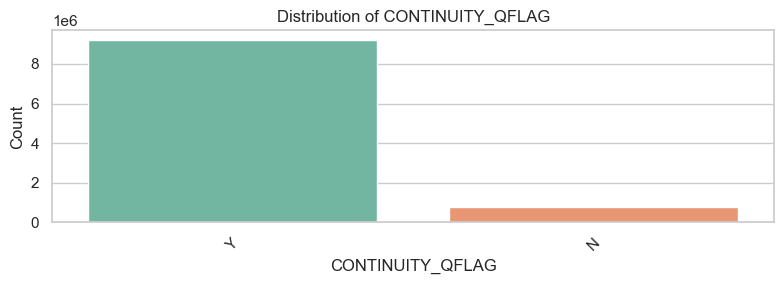

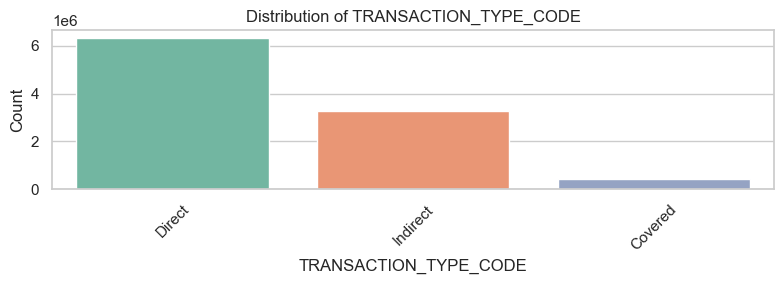

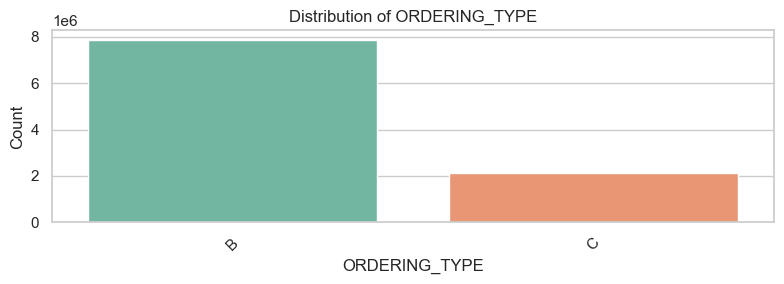

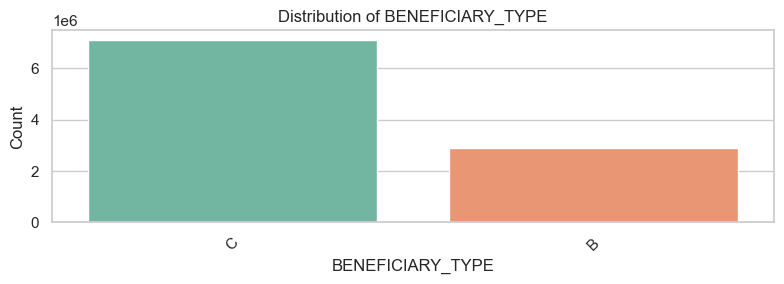

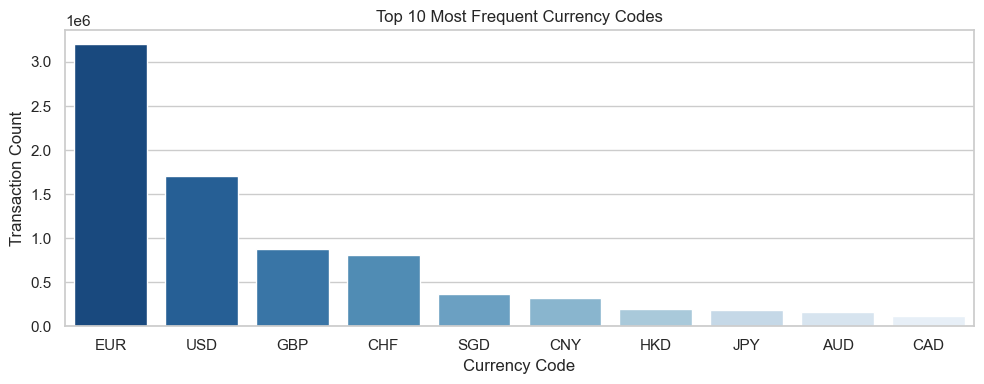

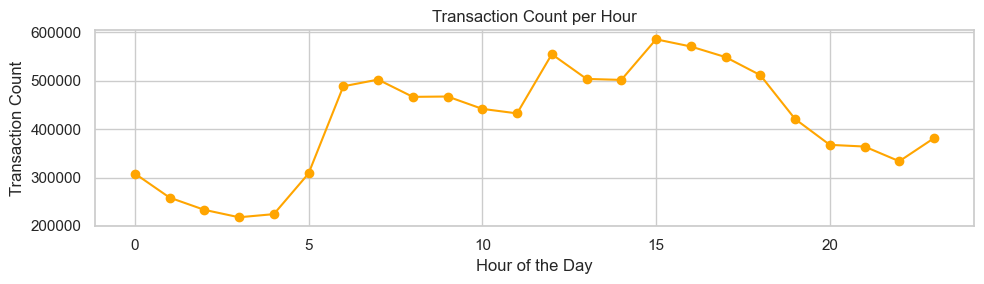

In [12]:
# 1. Bar charts for categorical columns (using top values for Currency to keep it clean)
categorical_cols = [
    'CONTINUITY_QFLAG',
    'TRANSACTION_TYPE_CODE',
    'ORDERING_TYPE',
    'BENEFICIARY_TYPE',
]

for col in categorical_cols:
  if col in df.columns:
    plt.figure(figsize=(8, 3))
    sns.countplot(
        data=df, x=col, order=df[col].value_counts().index, palette='Set2'
    )
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Clean Top 10 Currency Code Bar Chart
plt.figure(figsize=(10, 4))
top_currencies = df['CURRENCY_CODE'].value_counts().head(10)
sns.barplot(
    x=top_currencies.index, y=top_currencies.values, palette='Blues_r'
)
plt.title('Top 10 Most Frequent Currency Codes')
plt.xlabel('Currency Code')
plt.ylabel('Transaction Count')
plt.tight_layout()
plt.show()

# 2. Line Chart: Transaction Count per Hour
hourly_counts = df.groupby('hour').size()

plt.figure(figsize=(10, 3))
hourly_counts.plot(kind='line', marker='o', color='orange')
plt.title('Transaction Count per Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Transaction Count')
plt.grid(True)
plt.tight_layout()
plt.show()

In [50]:
# Create a sample or work with df to check currency vs country mismatch
# Note: Characters 5 and 6 of a BIC8 code usually represent the ISO country code (e.g., 'US', 'GB', 'DE')

# 1. Extract country code from BIC8 (characters 4 and 5 in Python 0-indexing)
df['bic_country'] = df['ORDERING_BIC8'].str.slice(4, 6)

# 2. Basic heuristic or mapping check (e.g., USD usually maps to US, EUR to Eurozone countries, GBP to GB, etc.)
# For a quick mismatch flag: check if currency code shares clues or if you have a country-currency mapping dictionary
currency_to_country = {
    'USD': 'US',
    'EUR': ['DE', 'FR', 'IT', 'ES', 'NL', 'BE', 'LU', 'AT', 'PT', 'IE', 'FI', 'GR'],
    'GBP': 'GB',
    'SGD': 'SG',
    'MYR': 'MY',
    'JPY': 'JP',
    'AUD': 'AU',
    'CAD': 'CA'
}

# Example validation function to flag currency-country mismatches
def check_currency_country_match(row):
    curr = row['CURRENCY_CODE']
    bic_cty = row['bic_country']
    
    if curr in currency_to_country:
        expected = currency_to_country[curr]
        if isinstance(expected, list):
            return bic_cty in expected
        else:
            return bic_cty == expected
    return True # Default True for rare/unmapped currencies

df['is_currency_country_matched'] = df.apply(check_currency_country_match, axis=1)

# Summary of mismatches
mismatch_count = (~df['is_currency_country_matched']).sum()
print(f"Total transactions where currency doesn't strictly match the primary bank country: {mismatch_count:,}")

Total transactions where currency doesn't strictly match the primary bank country: 1,328,353


# Bivariate Analysis & Currency Anomaly Breakdown

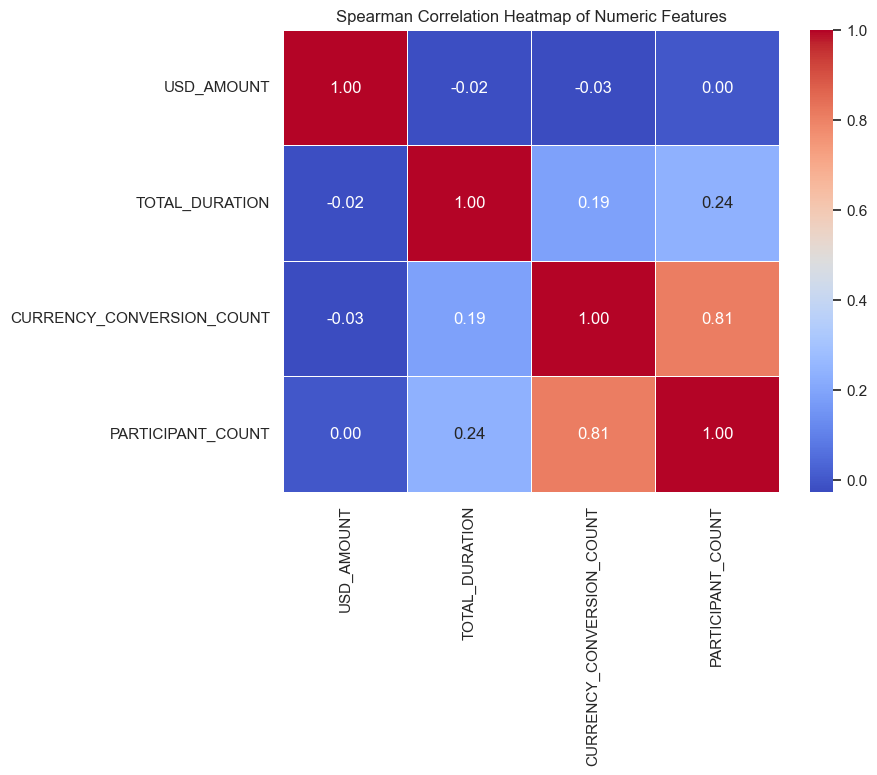

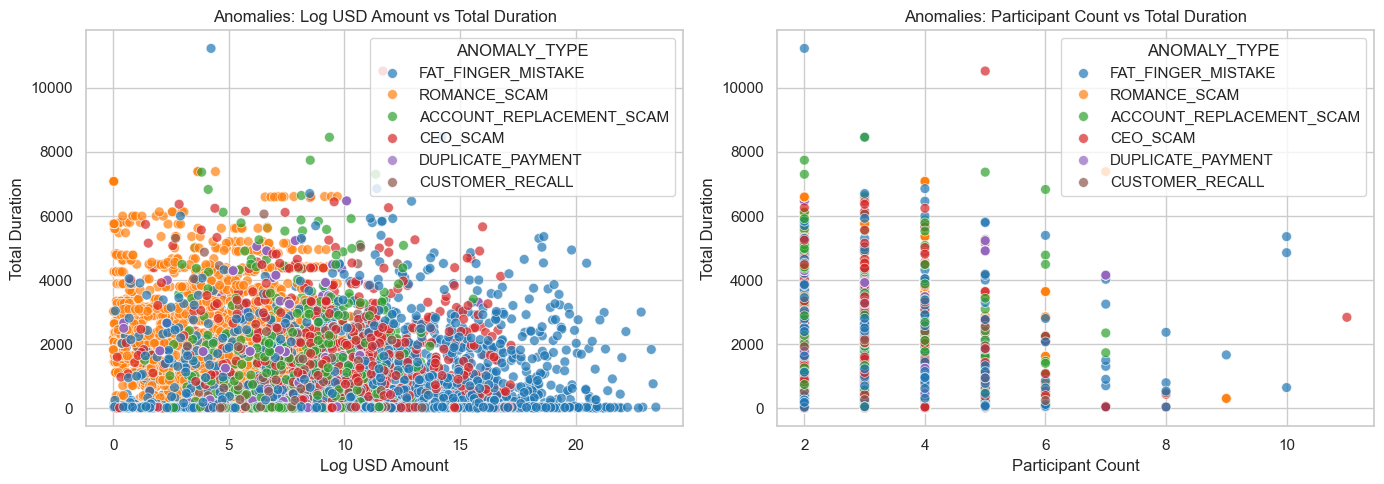

In [14]:
# Bivariate Analysis: Spearman Correlation Matrix & Heatmap
plt.figure(figsize=(8, 6))
numeric_subset = df[['USD_AMOUNT', 'TOTAL_DURATION', 'CURRENCY_CONVERSION_COUNT', 'PARTICIPANT_COUNT']]
corr_matrix = numeric_subset.corr(method='spearman')

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Spearman Correlation Heatmap of Numeric Features')
plt.show()

# Filter dataframe to show only anomalies for a clean scatter plot
anomalies_df = df[df['is_anomaly'] == True]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Log USD Amount vs Total Duration (Anomalies Only)
sns.scatterplot(
    data=anomalies_df,
    x='log_usd_amount',
    y='TOTAL_DURATION',
    hue='ANOMALY_TYPE',
    alpha=0.7,
    ax=axes[0],
    palette='tab10',
    s=50,  # Slightly larger points for visibility
)
axes[0].set_title('Anomalies: Log USD Amount vs Total Duration')
axes[0].set_xlabel('Log USD Amount')
axes[0].set_ylabel('Total Duration')

# 2. Participant Count vs Total Duration (Anomalies Only)
if 'PARTICIPANT_COUNT' in df.columns:
  sns.scatterplot(
      data=anomalies_df,
      x='PARTICIPANT_COUNT',
      y='TOTAL_DURATION',
      hue='ANOMALY_TYPE',
      alpha=0.7,
      ax=axes[1],
      palette='tab10',
      s=50,
  )
  axes[1].set_title('Anomalies: Participant Count vs Total Duration')
  axes[1].set_xlabel('Participant Count')
  axes[1].set_ylabel('Total Duration')

plt.tight_layout()
plt.show()

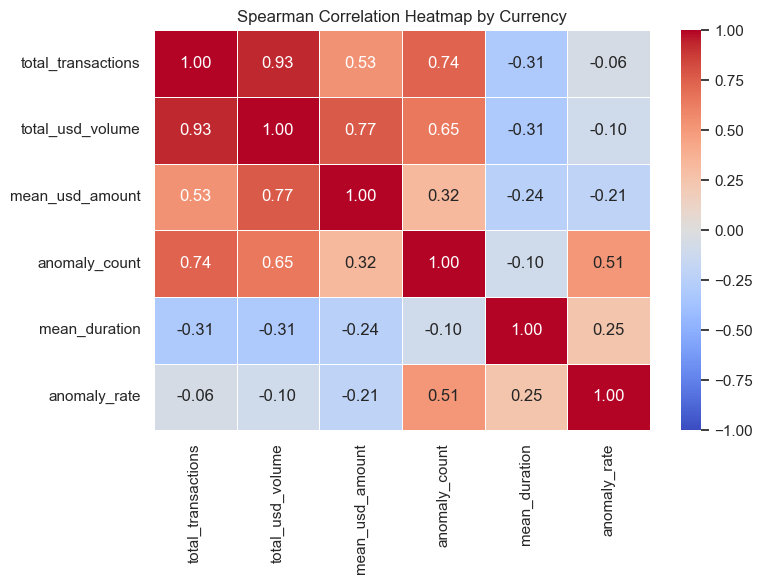

In [45]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Group by currency code to aggregate transaction metrics
currency_stats = df.groupby('CURRENCY_CODE').agg(
    total_transactions=('USD_AMOUNT', 'count'),
    total_usd_volume=('USD_AMOUNT', 'sum'),
    mean_usd_amount=('USD_AMOUNT', 'mean'),
    anomaly_count=('is_anomaly', 'sum'),
    mean_duration=('TOTAL_DURATION', 'mean')
).reset_index()

# 2. Calculate anomaly rate percentage per currency
currency_stats['anomaly_rate'] = (currency_stats['anomaly_count'] / currency_stats['total_transactions']) * 100

# 3. Compute the Spearman correlation matrix
spearman_corr = currency_stats[[
    'total_transactions', 
    'total_usd_volume', 
    'mean_usd_amount', 
    'anomaly_count', 
    'mean_duration', 
    'anomaly_rate'
]].corr(method='spearman')

# 4. Plot the Spearman correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Spearman Correlation Heatmap by Currency')
plt.tight_layout()
plt.show()

# Boxplots Split by ANOMALY_TYPE

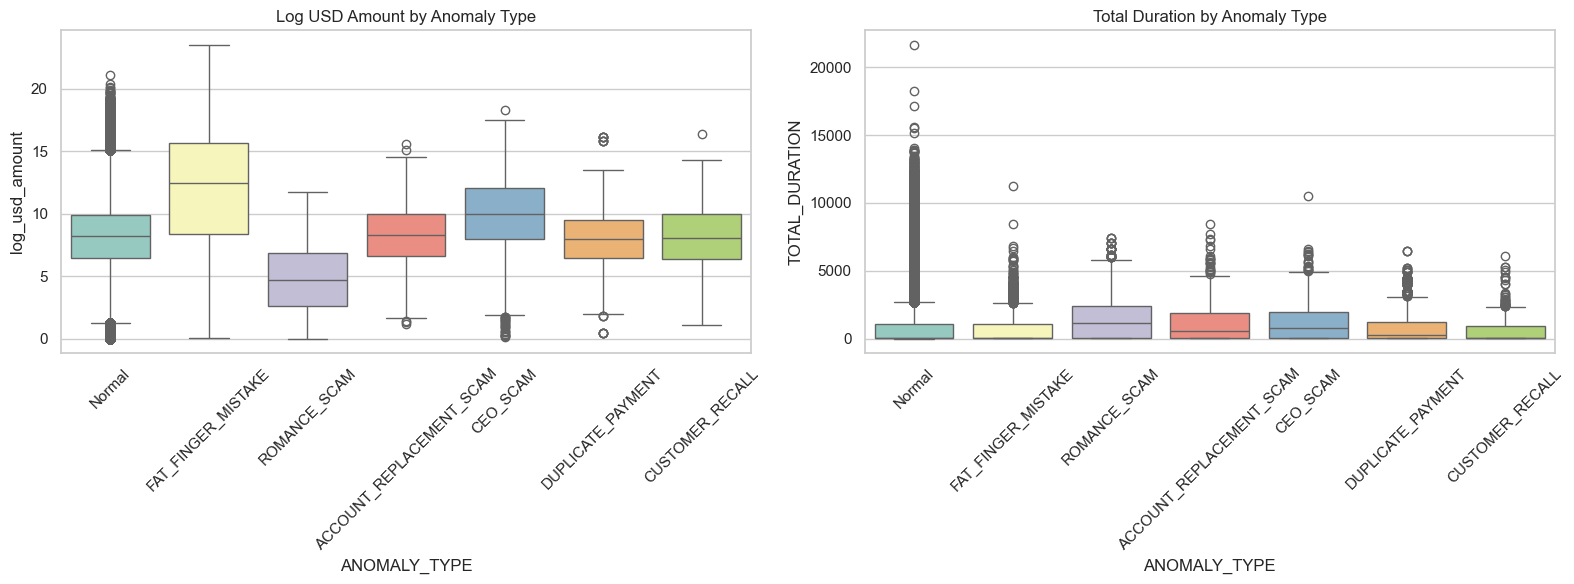

In [15]:
# Boxplots of USD Amount and Total Duration split by Anomaly Type
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Log USD Amount by Anomaly Type
sns.boxplot(
    data=df,
    x='ANOMALY_TYPE',
    y='log_usd_amount',
    ax=axes[0],
    palette='Set3',
)
axes[0].set_title('Log USD Amount by Anomaly Type')
axes[0].tick_params(axis='x', rotation=45)

# Total Duration by Anomaly Type
sns.boxplot(
    data=df, x='ANOMALY_TYPE', y='TOTAL_DURATION', ax=axes[1], palette='Set3'
)
axes[1].set_title('Total Duration by Anomaly Type')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

<Figure size 1000x500 with 0 Axes>

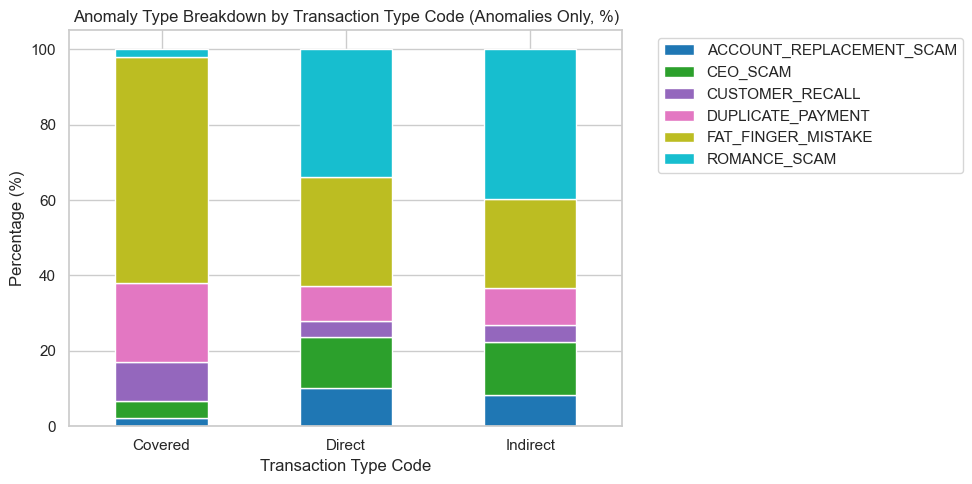

C:\Users\chowy\AppData\Local\Temp\ipykernel_34452\60706781.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  anomalies_df['ordering_beneficiary'] = (


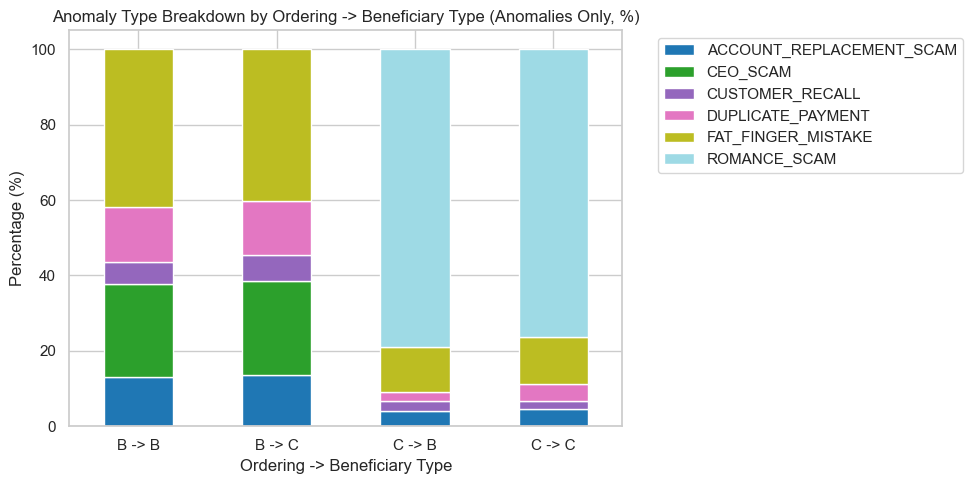

In [17]:
# Filter dataframe to include ONLY anomalies
anomalies_df = df[df['is_anomaly'] == True]

# 100% Stacked Bar: Anomaly Type breakdown by Transaction Type Code
plt.figure(figsize=(10, 5))
tx_anomaly = pd.crosstab(
    anomalies_df['TRANSACTION_TYPE_CODE'],
    anomalies_df['ANOMALY_TYPE'],
    normalize='index',
) * 100
tx_anomaly.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='tab10')
plt.title(
    'Anomaly Type Breakdown by Transaction Type Code (Anomalies Only, %)'
)
plt.xlabel('Transaction Type Code')
plt.ylabel('Percentage (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 100% Stacked Bar: Anomaly Type breakdown by Ordering -> Beneficiary Type
anomalies_df['ordering_beneficiary'] = (
    anomalies_df['ORDERING_TYPE'].astype(str)
    + ' -> '
    + anomalies_df['BENEFICIARY_TYPE'].astype(str)
)
ob_anomaly = pd.crosstab(
    anomalies_df['ordering_beneficiary'],
    anomalies_df['ANOMALY_TYPE'],
    normalize='index',
) * 100
ob_anomaly.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='tab20')
plt.title('Anomaly Type Breakdown by Ordering -> Beneficiary Type (Anomalies Only, %)')
plt.xlabel('Ordering -> Beneficiary Type')
plt.ylabel('Percentage (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Clean Heatmap Crosstab (ORDERING_TYPE × BENEFICIARY_TYPE for Anomalies)

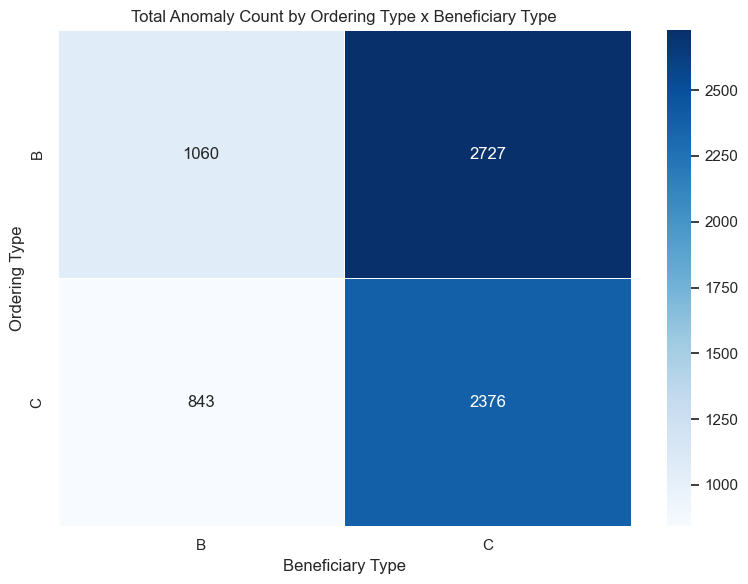

In [18]:
# Heatmap Crosstab: Ordering Type x Beneficiary Type using only anomalies
plt.figure(figsize=(8, 6))

# Count the frequency of anomaly types across ordering and beneficiary types
pivot_anomaly_count = pd.crosstab(
    anomalies_df['ORDERING_TYPE'], anomalies_df['BENEFICIARY_TYPE']
)

sns.heatmap(
    pivot_anomaly_count, annot=True, cmap='Blues', fmt='d', linewidths=0.5
)
plt.title('Total Anomaly Count by Ordering Type x Beneficiary Type')
plt.xlabel('Beneficiary Type')
plt.ylabel('Ordering Type')
plt.tight_layout()
plt.show()

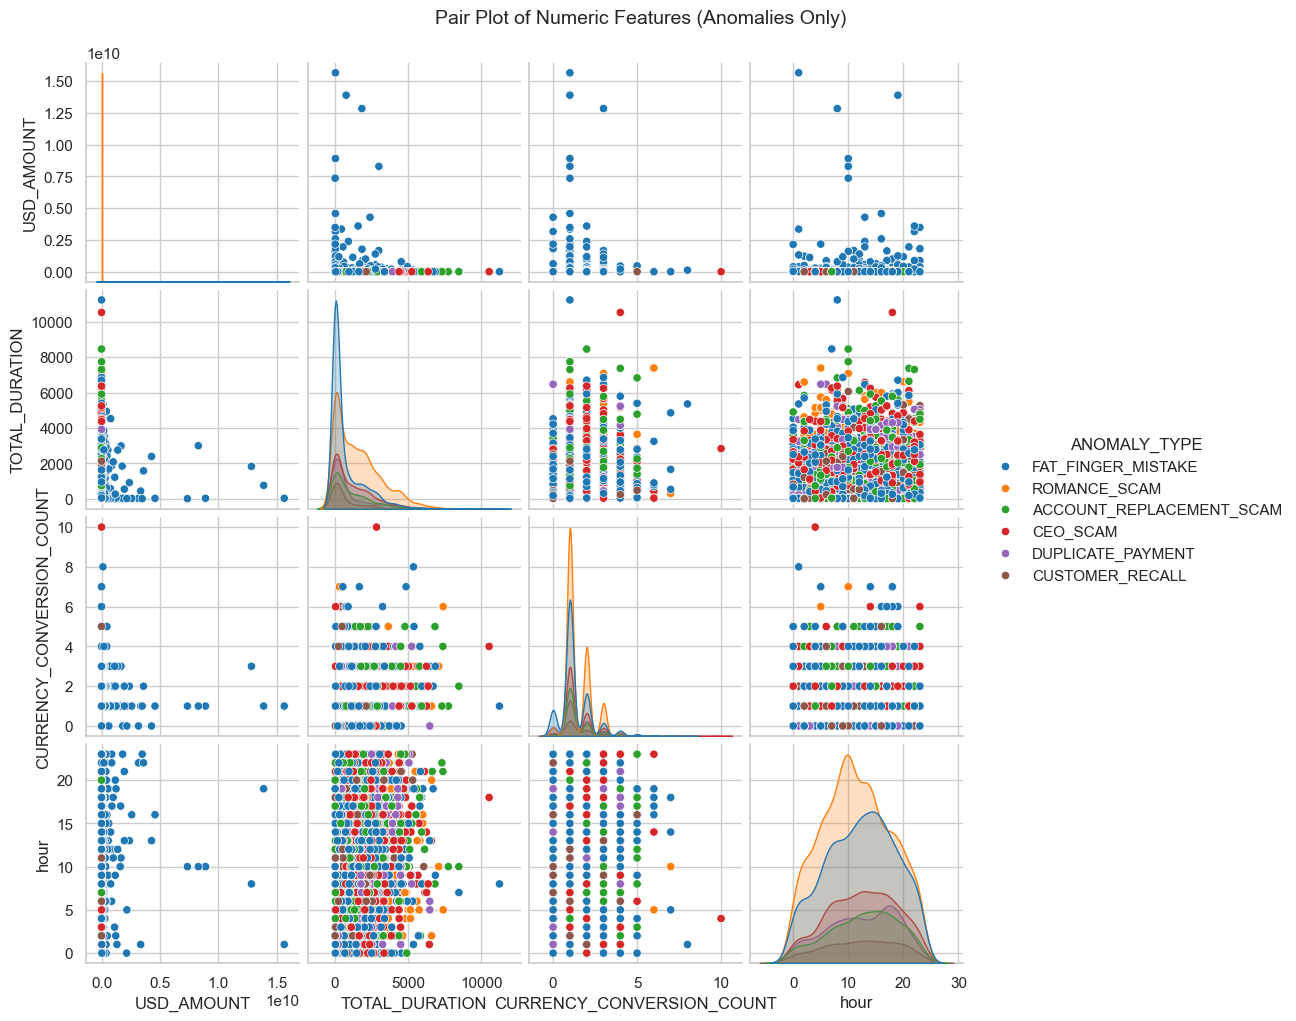

In [20]:
# Create a new cell and run this for a clean pair plot showing only anomalies
# Filter sample to include only anomalies
anomalies_sample = df[df['is_anomaly'] == True]

# If you want to include a few normal samples for comparison, you can combine them like this:
# normal_sample = df[df['is_anomaly'] == False].sample(n=500, random_state=42)
# sample_df = pd.concat([anomalies_sample, normal_sample])

pairplot_cols = [
    'USD_AMOUNT',
    'TOTAL_DURATION',
    'CURRENCY_CONVERSION_COUNT',
    'hour',
    'ANOMALY_TYPE',
]

sns.pairplot(
    anomalies_sample[pairplot_cols],
    hue='ANOMALY_TYPE',
    palette='tab10',
    diag_kind='kde',
)
plt.suptitle('Pair Plot of Numeric Features (Anomalies Only)', y=1.02, fontsize=14)
plt.show()

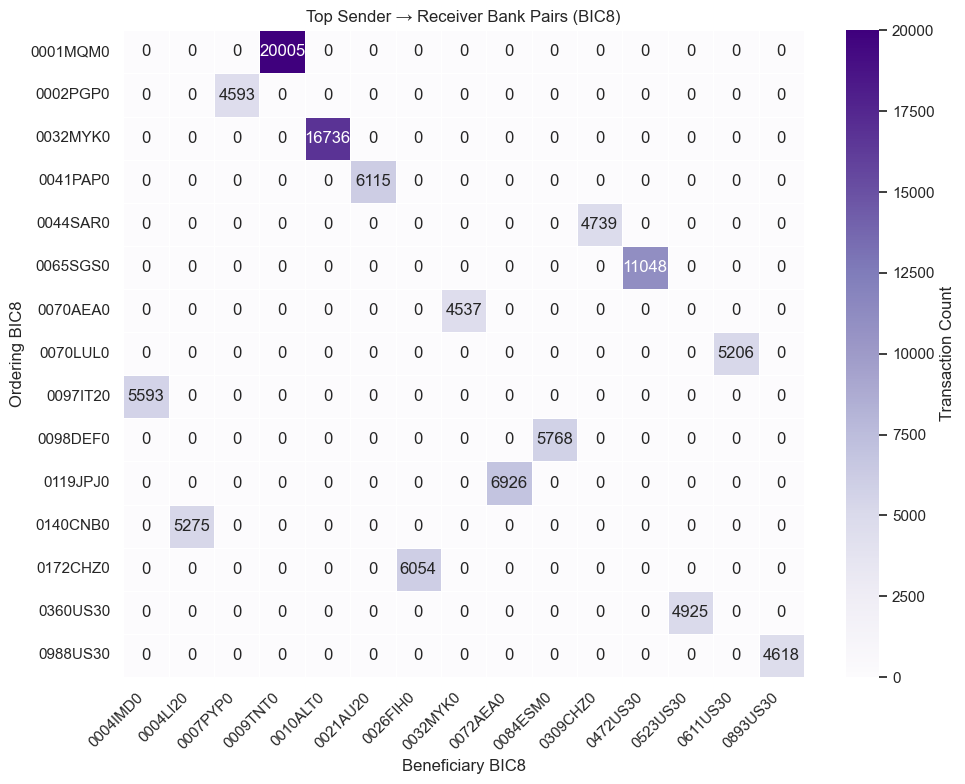

In [22]:
# Create a new cell and run this for the Top Sender -> Receiver Bank Pairs Heatmap (Safe version)
plt.figure(figsize=(10, 8))

# Explicitly cast both columns to string to avoid datatype/NaN errors during concatenation
df['bank_pair'] = (
    df['ORDERING_BIC8'].astype(str) + ' → ' + df['BENEFICIARY_BIC8'].astype(str)
)

# Get the top 15 most frequent bank pairs to keep the heatmap readable
top_pairs = df['bank_pair'].value_counts().head(15)
top_df = df[df['bank_pair'].isin(top_pairs.index)]

# Create crosstab pivot table for the top pairs
pair_pivot = pd.crosstab(top_df['ORDERING_BIC8'], top_df['BENEFICIARY_BIC8'])

sns.heatmap(
    pair_pivot,
    annot=True,
    cmap='Purples',
    fmt='d',
    linewidths=0.5,
    cbar_kws={'label': 'Transaction Count'},
)
plt.title('Top Sender → Receiver Bank Pairs (BIC8)')
plt.xlabel('Beneficiary BIC8')
plt.ylabel('Ordering BIC8')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Original dataset size: 10,000,000 rows
Sampled dataset size: 300,000 rows


<Figure size 1200x1000 with 0 Axes>

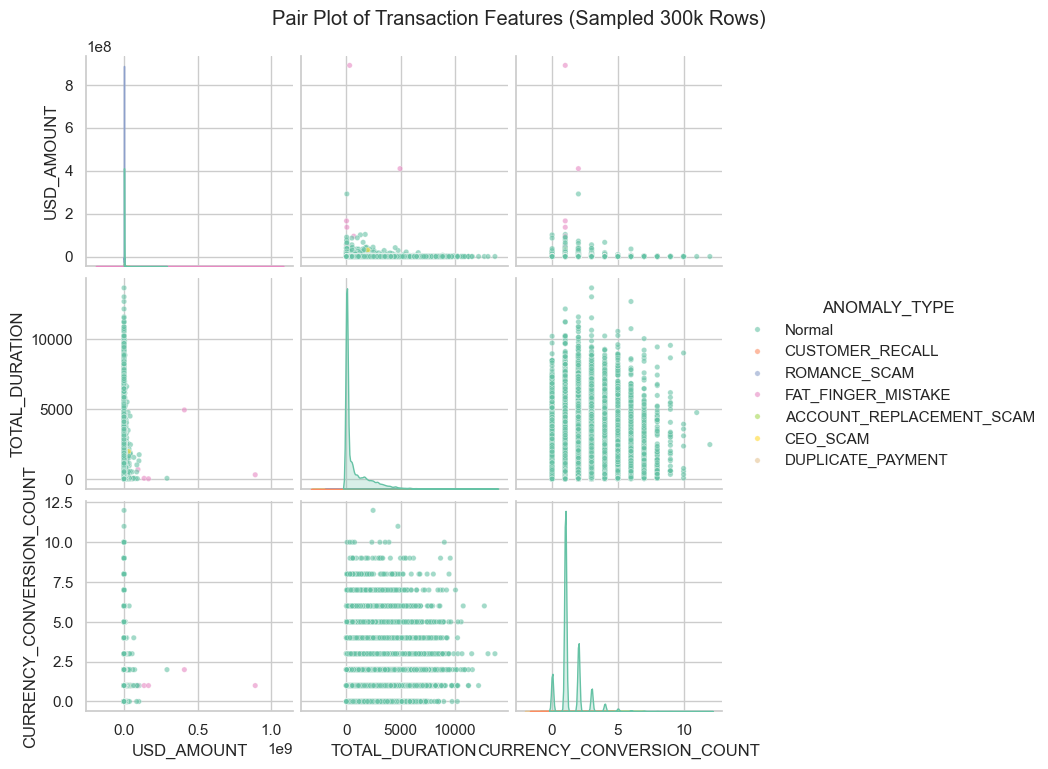

In [46]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Take a random sample of 300,000 rows to prevent freezing (random_state ensures reproducibility)
df_sample = df.sample(n=300000, random_state=42)

print(f"Original dataset size: {len(df):,} rows")
print(f"Sampled dataset size: {len(df_sample):,} rows")

# 2. Generate a faster Pair Plot on the sampled data
# Selecting key numeric and anomaly features for the pairplot
pairplot_features = ['USD_AMOUNT', 'TOTAL_DURATION', 'CURRENCY_CONVERSION_COUNT', 'ANOMALY_TYPE']

plt.figure(figsize=(12, 10))
sns.pairplot(
    df_sample[pairplot_features], 
    hue='ANOMALY_TYPE', 
    palette='Set2', 
    diag_kind='kde',
    plot_kws={'alpha': 0.6, 's': 15}
)
plt.suptitle('Pair Plot of Transaction Features (Sampled 300k Rows)', y=1.02)
plt.show()

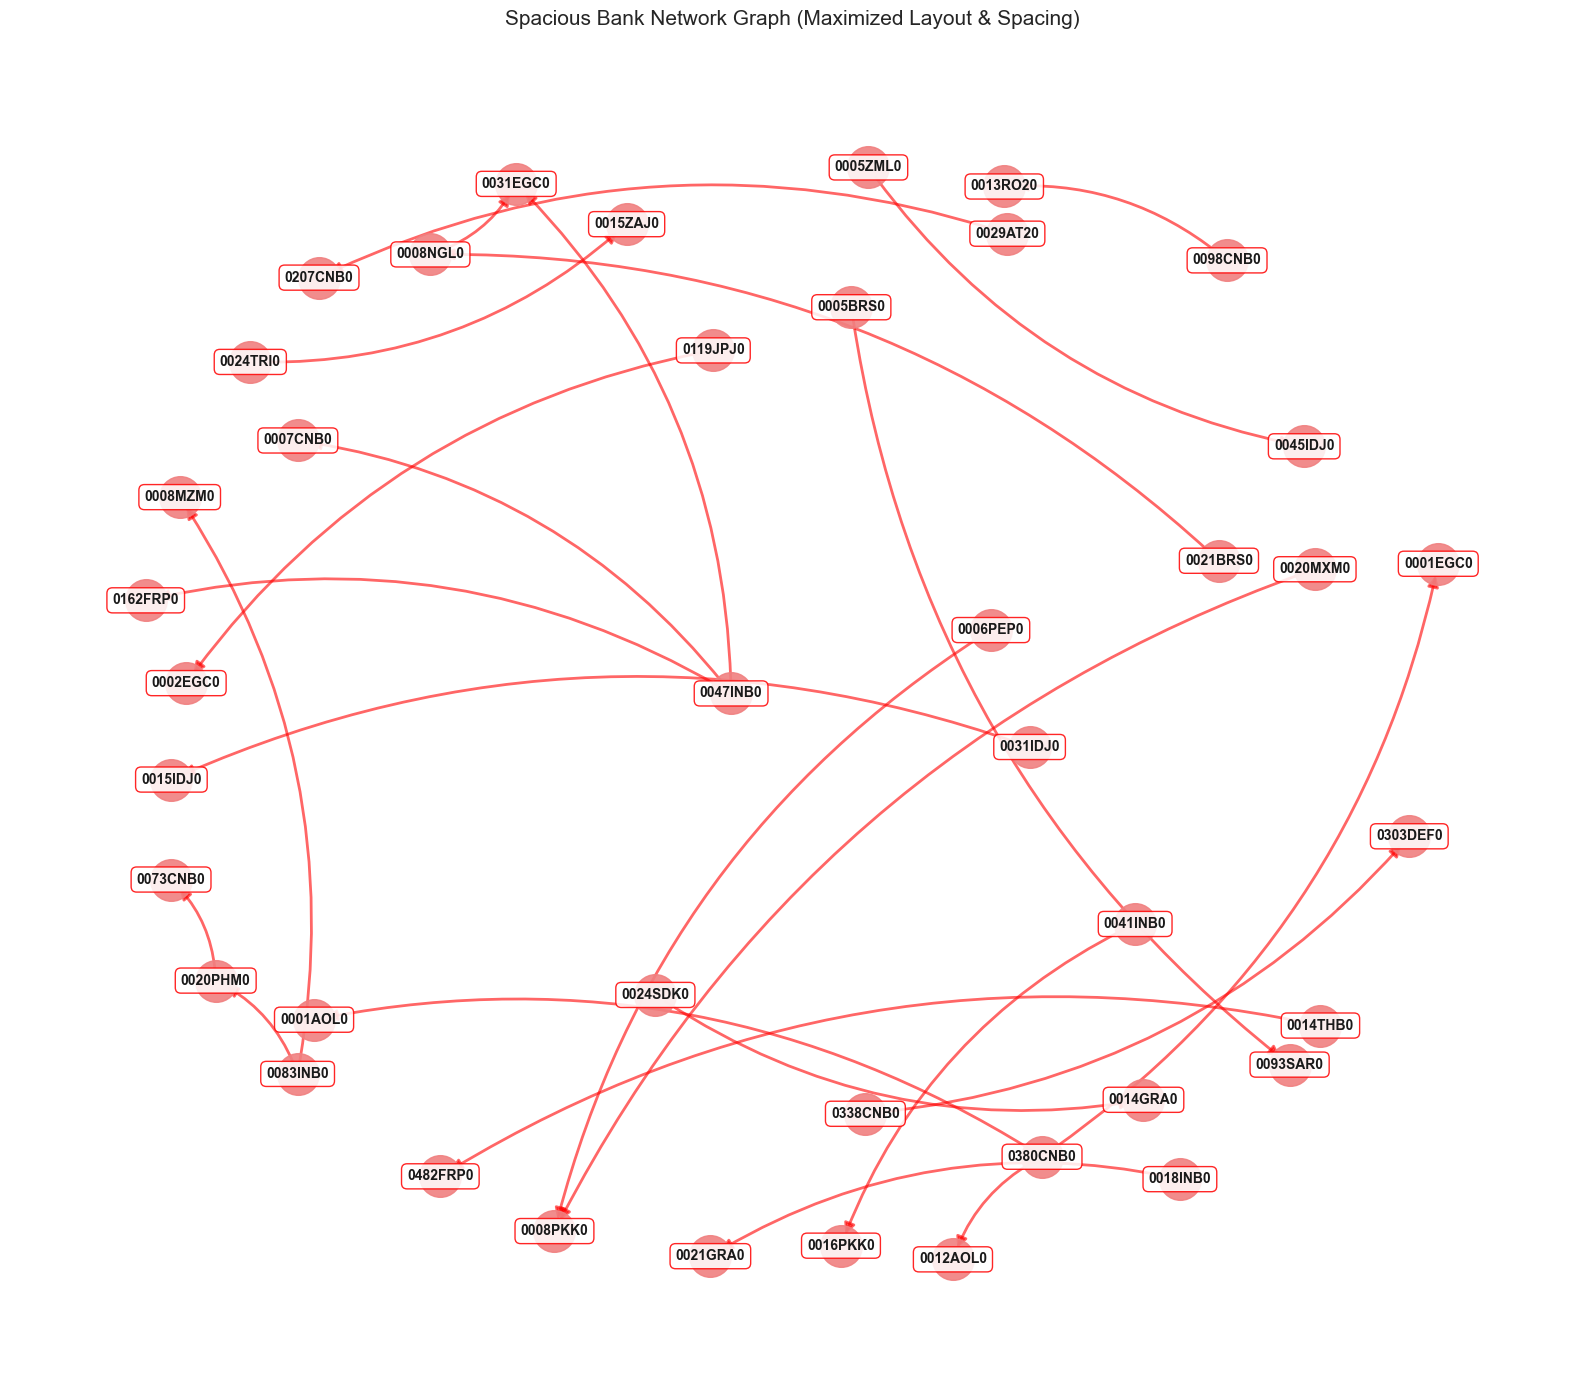

In [31]:
# Create a new cell and run this for an expanded, spacious Network Graph
import networkx as nx

# 1. Filter dataset for anomalies and keep top 25 paths to prevent overcrowding
anomalies_net = df[df['is_anomaly'] == True].copy()
anomalies_net['bank_pair'] = (
    anomalies_net['ORDERING_BIC8'].astype(str)
    + ' → '
    + anomalies_net['BENEFICIARY_BIC8'].astype(str)
)

top_anomaly_pairs = anomalies_net['bank_pair'].value_counts().head(25).index
net_subset = anomalies_net[anomalies_net['bank_pair'].isin(top_anomaly_pairs)]

# Initialize directed graph
G = nx.DiGraph()
for _, row in net_subset.iterrows():
  source = row['ORDERING_BIC8']
  target = row['BENEFICIARY_BIC8']
  G.add_edge(source, target)

# 2. Make the canvas much larger (16x14) and increase k to 1.2 for massive node spacing
plt.figure(figsize=(16, 14))
pos = nx.spring_layout(G, k=1.2, seed=42)

# 3. Draw nodes, curved edges, and labels with a clean white bounding box
nx.draw_networkx_nodes(
    G, pos, node_size=900, node_color='lightcoral', alpha=0.9
)
nx.draw_networkx_edges(
    G,
    pos,
    edge_color='red',
    alpha=0.6,
    width=2,
    arrows=True,
    arrowsize=16,
    connectionstyle='arc3,rad=0.2',
)
nx.draw_networkx_labels(
    G,
    pos,
    font_size=10,
    font_weight='bold',
    bbox=dict(boxstyle='round,pad=0.4', fc='white', ec='red', alpha=0.85),
)

plt.title(
    'Spacious Bank Network Graph (Maximized Layout & Spacing)',
    fontsize=15,
    pad=20,
)
plt.axis('off')
plt.tight_layout()
plt.show()

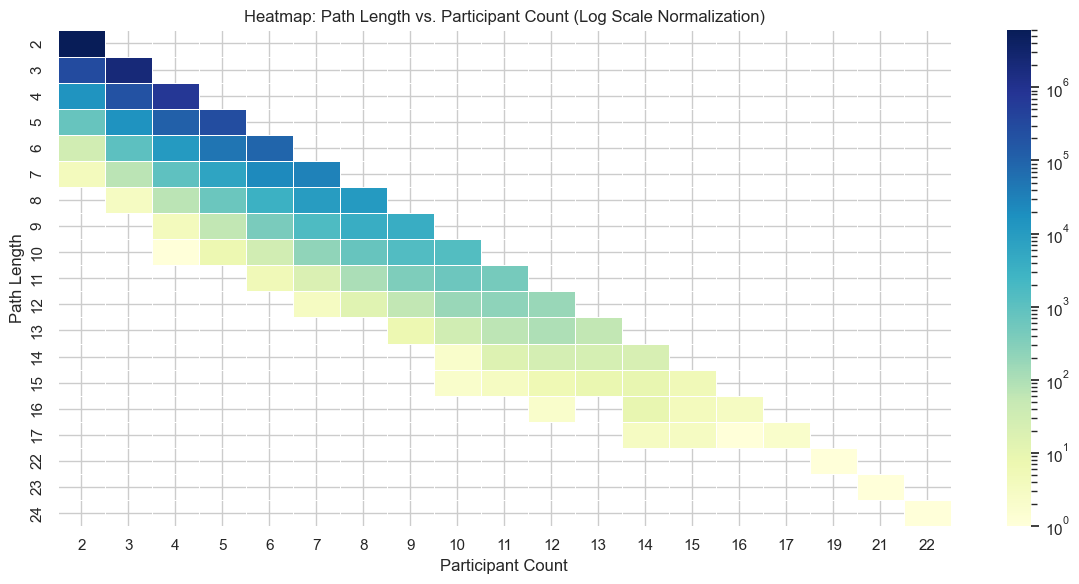

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LogNorm  # Import LogNorm for logarithmic scaling

# Heatmap Crosstab: Path Length vs Participant Count (Using LogNorm to fix the yellow washout)
plt.figure(figsize=(12, 6))

path_participant_ct = pd.crosstab(df['path_length'], df['PARTICIPANT_COUNT'])

sns.heatmap(
    path_participant_ct,
    cmap='YlGnBu',
    norm=LogNorm(),  # Applies a logarithmic transformation so low-frequency cells become visible!
    annot=False,
    linewidths=0.5,
)

plt.title(
    'Heatmap: Path Length vs. Participant Count (Log Scale Normalization)'
)
plt.xlabel('Participant Count')
plt.ylabel('Path Length')
plt.tight_layout()
plt.show()

<Figure size 1400x500 with 0 Axes>

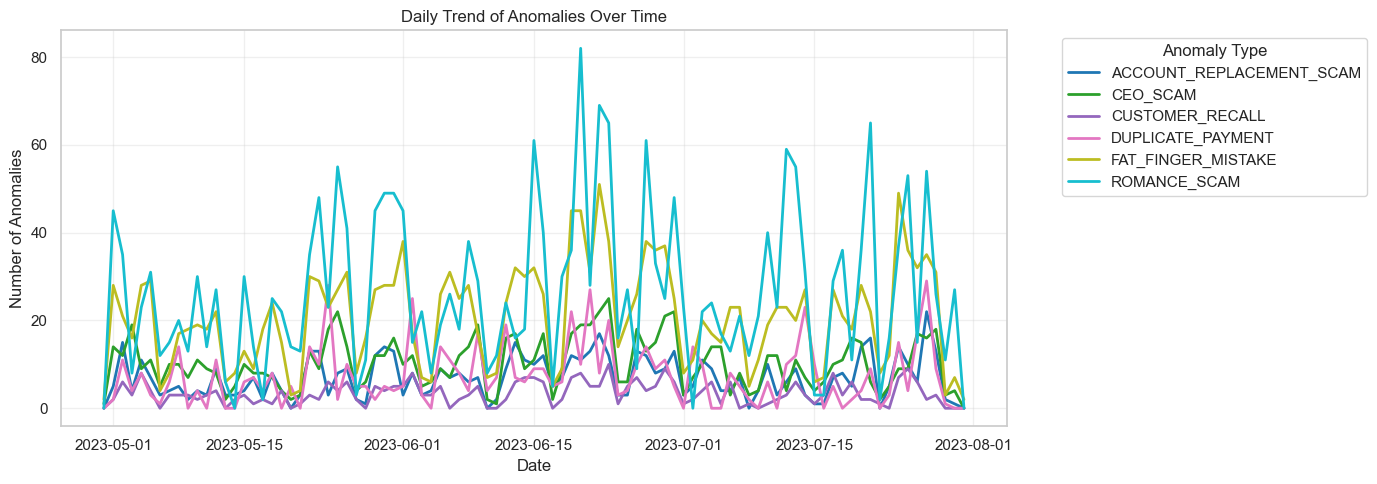

In [35]:
# Create a new cell and run this for Anomalies Over Time
plt.figure(figsize=(14, 5))

# Extract date from datetime
df['date'] = df['datetime'].dt.date

# Filter for anomalies and aggregate daily counts by anomaly type
anomalies_time = (
    df[df['is_anomaly'] == True]
    .groupby(['date', 'ANOMALY_TYPE'])
    .size()
    .unstack(fill_value=0)
)

# Plot daily trends
anomalies_time.plot(kind='line', figsize=(14, 5), linewidth=2, colormap='tab10')
plt.title('Daily Trend of Anomalies Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Anomalies')
plt.legend(title='Anomaly Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

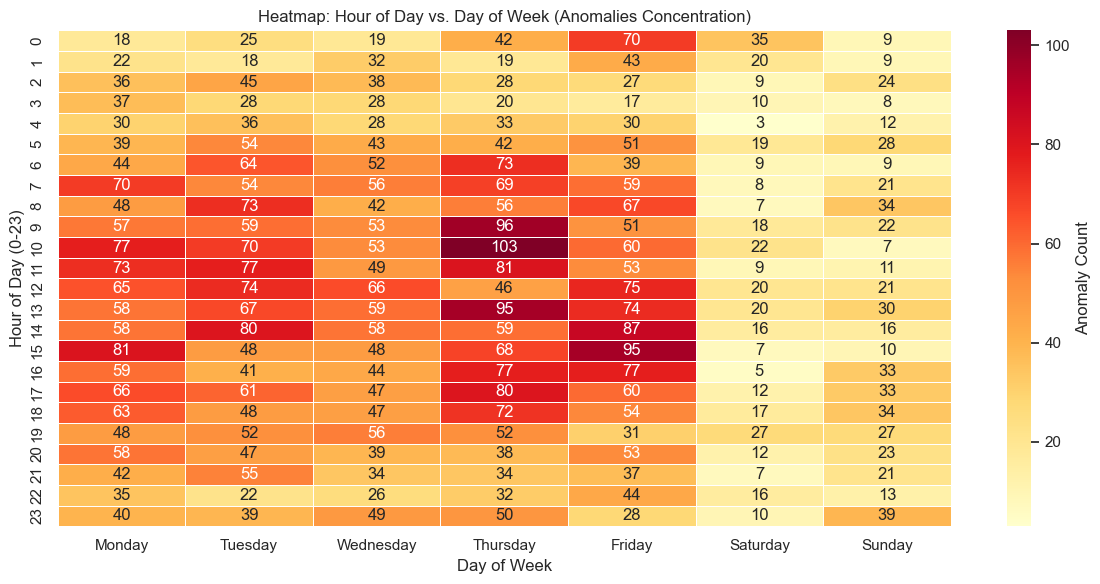

In [36]:
# Create a new cell and run this for the Hour x Day-of-Week Heatmap
plt.figure(figsize=(12, 6))

# Define correct chronological day order
days_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday',
]

# Create crosstab pivot table using only anomalies
anomalies_df = df[df['is_anomaly'] == True]
hour_day_crosstab = pd.crosstab(
    anomalies_df['hour'], anomalies_df['day_of_week']
)

# Reindex columns to follow proper weekday order if present
existing_days = [d for d in days_order if d in hour_day_crosstab.columns]
hour_day_crosstab = hour_day_crosstab[existing_days]

sns.heatmap(
    hour_day_crosstab,
    cmap='YlOrRd',
    annot=True,
    fmt='d',
    linewidths=0.5,
    cbar_kws={'label': 'Anomaly Count'},
)
plt.title('Heatmap: Hour of Day vs. Day of Week (Anomalies Concentration)')
plt.xlabel('Day of Week')
plt.ylabel('Hour of Day (0-23)')
plt.tight_layout()
plt.show()

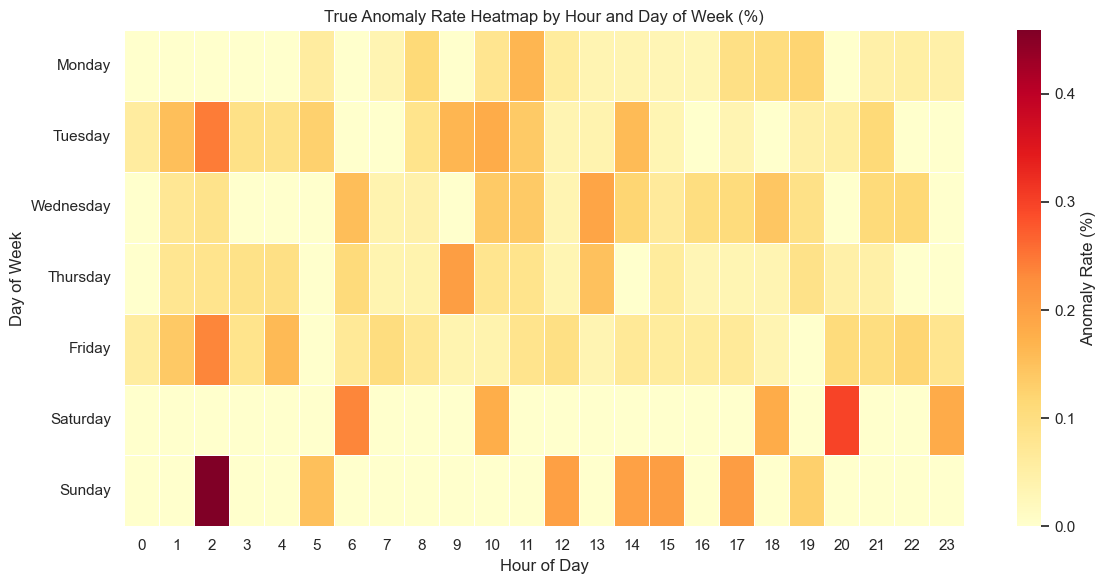

In [48]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Take a 300k sample for performance
df_sample = df.sample(n=300000, random_state=42)

# 2. Define the correct chronological order for days of the week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Convert day_of_week into an ordered categorical type
df_sample['day_of_week'] = pd.Categorical(df_sample['day_of_week'], categories=day_order, ordered=True)

# 3. Group by day and hour
time_agg = df_sample.groupby(['day_of_week', 'hour'], observed=False).agg(
    total_transactions=('USD_AMOUNT', 'count'),
    anomaly_count=('is_anomaly', 'sum')
).reset_index()

# Calculate anomaly rate percentage
time_agg['anomaly_rate'] = (time_agg['anomaly_count'] / time_agg['total_transactions']) * 100

# 4. Pivot into matrix format (Days as rows, Hours as columns)
pivot_rate = time_agg.pivot(index='day_of_week', columns='hour', values='anomaly_rate')

# 5. Plot the properly ordered Heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(pivot_rate, cmap='YlOrRd', annot=False, fmt='.2f', linewidths=0.5, cbar_kws={'label': 'Anomaly Rate (%)'})
plt.title('True Anomaly Rate Heatmap by Hour and Day of Week (%)')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.tight_layout()
plt.show()

# Reverse-Engineering with a Decision Tree

In [7]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.preprocessing import LabelEncoder

# Prepare data for the decision tree (predicting anomaly vs normal, or specific anomaly types)
# Let's create a binary target first: Is it an anomaly or normal?
df['is_anomaly'] = df['ANOMALY_TYPE'] != 'Normal'

# Select features for the tree
feature_cols = ['USD_AMOUNT', 'TOTAL_DURATION', 'CURRENCY_CONVERSION_COUNT', 'PARTICIPANT_COUNT', 'hour']
X = df[feature_cols]
y = df['is_anomaly']

# Train a shallow decision tree (depth 4)
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X, y)

# Print the rules learned by the tree
tree_rules = export_text(tree, feature_names=feature_cols)
print("--- Decision Tree Rules for Predicting Anomalies ---")
print(tree_rules)

--- Decision Tree Rules for Predicting Anomalies ---
|--- USD_AMOUNT <= 119195292.00
|   |--- USD_AMOUNT <= 52247776.00
|   |   |--- USD_AMOUNT <= 4935574.75
|   |   |   |--- USD_AMOUNT <= 0.84
|   |   |   |   |--- class: False
|   |   |   |--- USD_AMOUNT >  0.84
|   |   |   |   |--- class: False
|   |   |--- USD_AMOUNT >  4935574.75
|   |   |   |--- USD_AMOUNT <= 14220759.00
|   |   |   |   |--- class: False
|   |   |   |--- USD_AMOUNT >  14220759.00
|   |   |   |   |--- class: False
|   |--- USD_AMOUNT >  52247776.00
|   |   |--- USD_AMOUNT <= 70201624.00
|   |   |   |--- USD_AMOUNT <= 52867008.00
|   |   |   |   |--- class: False
|   |   |   |--- USD_AMOUNT >  52867008.00
|   |   |   |   |--- class: False
|   |   |--- USD_AMOUNT >  70201624.00
|   |   |   |--- USD_AMOUNT <= 71537516.00
|   |   |   |   |--- class: True
|   |   |   |--- USD_AMOUNT >  71537516.00
|   |   |   |   |--- class: False
|--- USD_AMOUNT >  119195292.00
|   |--- USD_AMOUNT <= 247699672.00
|   |   |--- TOTAL_DUR

# Feature Engineering

In [8]:
# Feature Engineering steps
# 1. Path Length (counting nodes separated by semicolon in BIC8_PATH)
df['path_length'] = df['BIC8_PATH'].astype(str).str.count(';') + 1

# 2. Path length minus participant count discrepancy check
df['path_participant_diff'] = df['path_length'] - df['PARTICIPANT_COUNT']

# 3. Amount per hop
df['amount_per_hop'] = df['USD_AMOUNT'] / df['path_length']

# 4. Same country check (BIC characters 5 and 6 represent the country code)
# Extract country codes if BIC8 is at least 6 characters long
df['ordering_country'] = df['ORDERING_BIC8'].str[4:6]
df['beneficiary_country'] = df['BENEFICIARY_BIC8'].str[4:6]
df['is_same_country'] = df['ordering_country'] == df['beneficiary_country']

print("Feature engineering complete!")
print(df[['USD_AMOUNT', 'path_length', 'PARTICIPANT_COUNT', 'amount_per_hop', 'is_same_country']].head())

Feature engineering complete!
   USD_AMOUNT  path_length  PARTICIPANT_COUNT  amount_per_hop  is_same_country
0         500            2                  2             250             True
1        1390            2                  2             695            False
2        3972            2                  2            1986            False
3        1921            3                  3             640            False
4       22131            2                  2           11065            False


# Engineered Feature Analysis (Country & Amount per Hop)

In [9]:
# Analyze anomaly rates using our newly engineered features
print("--- Anomaly Rate by Same Country Status ---")
print(pd.crosstab(df['is_same_country'], df['ANOMALY_TYPE'], normalize='index') * 100)

print("\n--- Summary Statistics of Amount Per Hop by Anomaly Type ---")
print(df.groupby('ANOMALY_TYPE')['amount_per_hop'].agg(['mean', 'median', 'std']))

# Show raw transaction counts instead of percentages
print(pd.crosstab(df['is_same_country'], df['ANOMALY_TYPE']))

--- Anomaly Rate by Same Country Status ---
ANOMALY_TYPE     ACCOUNT_REPLACEMENT_SCAM  CEO_SCAM  CUSTOMER_RECALL  \
is_same_country                                                        
False                                   0         0                0   
True                                    0         0                0   

ANOMALY_TYPE     DUPLICATE_PAYMENT  FAT_FINGER_MISTAKE  Normal  ROMANCE_SCAM  
is_same_country                                                               
False                            0                   0     100             0  
True                             0                   0     100             0  

--- Summary Statistics of Amount Per Hop by Anomaly Type ---
                             mean  median       std
ANOMALY_TYPE                                       
ACCOUNT_REPLACEMENT_SCAM    25801    1555    150070
CEO_SCAM                   577346    7831   2173880
CUSTOMER_RECALL             36825    1171    251859
DUPLICATE_PAYMENT           6